In [ ]:
%pip install -q opencv-python-headless scikit-learn seaborn

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import cv2

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
OpenCV version: 4.14.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
%pip install -q kaggle

In [ ]:
!kaggle datasets download -d msambare/fer2013 -p /content

Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
100% 60.3M/60.3M [00:00<00:00, 120MB/s]



In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from PIL import Image
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models, regularizers, optimizers
from tensorflow.keras.applications import VGG16, ResNet50V2
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard, CSVLogger
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Dropout, Flatten, Dense, Activation, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from keras.utils import plot_model
from tensorflow.keras.layers import Input

In [ ]:

import zipfile
import os

zip_path = '/content/fer2013.zip'
extract_path = '/content'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Files in /content:", os.listdir('/content'))


Extraction completed!
Files in /content: ['.config', 'test', 'train', 'fer2013.zip', 'sample_data']


In [ ]:
# Define your project name
project_name = 'FER_2013_Emotion_Detection'

# List your models
model_names = [
    'Custom_CNN_From_Scratch',
    'Custom_CNN_With_Augmentation',
    'VGG16_Transfer_Learning',
    'ResNet50_Transfer_Learning'
]

base_dir = '/content'
os.makedirs(os.path.join(base_dir, project_name),exist_ok=True)
for model_name in model_names:
    os.makedirs(os.path.join(base_dir, project_name, model_name),exist_ok=True)

In [ ]:

import os

print("Current directory:", os.getcwd())
print("Contents of /content:")

for item in os.listdir('/content'):
    print(item)


Current directory: /content
Contents of /content:
.config
test
train
fer2013.zip
FER_2013_Emotion_Detection
sample_data


In [ ]:
emotions=os.listdir('/content/train/')

In [ ]:
emotions_count={}
for emotion in emotions:
  emotions_count[emotion]=len(os.listdir('/content/train/'+emotion))

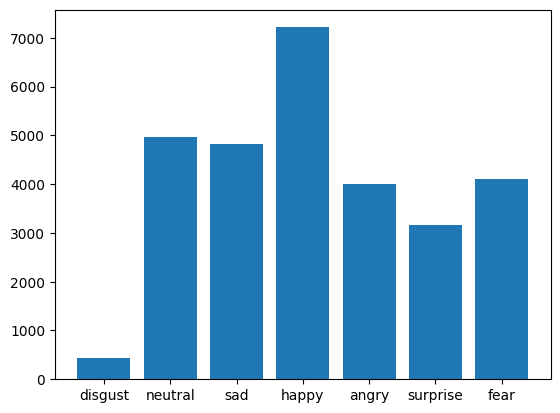

In [ ]:
plt.bar(emotions_count.keys(),emotions_count.values())
plt.show()

# Data Cleaning

In [ ]:

import os
from PIL import Image

image_exts = ['.jpeg', '.jpg', '.png']

for dir_path, folders, files in os.walk('/content/train'):
    for file in files:
        file_path = os.path.join(dir_path, file)

        try:
            # Check whether the file has an allowed extension
            if os.path.splitext(file)[1].lower() not in image_exts:
                print(f"Removing file: {file}")
                os.remove(file_path)
                continue

            # Check whether the image can actually be opened
            with Image.open(file_path) as img:
                img.verify()

        except Exception as e:
            print(f"Removing invalid image {file}: {e}")
            if os.path.exists(file_path):
                os.remove(file_path)

print("Image cleaning completed!")


Image cleaning completed!


Data Analysis

In [ ]:
def count_files_in_directory(directory,set_name):
    counts = {}
    for dir_path,folders,files in os.walk(directory):
      for folder in folders:
        counts[folder]=len(os.listdir(os.path.join(dir_path,folder)))

    df = pd.DataFrame(counts,index=[set_name])
    return df

In [ ]:
df_train=count_files_in_directory('/content/train','train')
df_test=count_files_in_directory('/content/test','test')
print(df_train)
print(df_test)

       disgust  neutral   sad  happy  angry  surprise  fear
train      436     4965  4830   7215   3995      3171  4097
      disgust  neutral   sad  happy  angry  surprise  fear
test      111     1233  1247   1774    958       831  1024


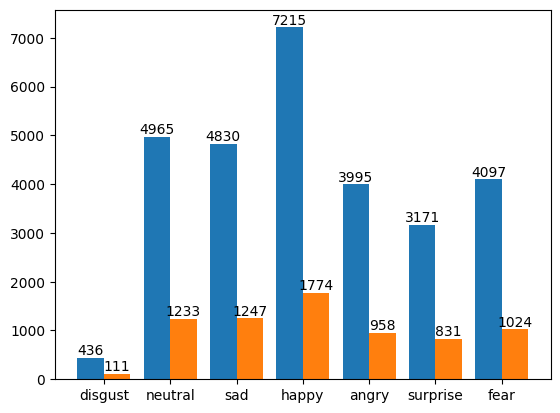

In [ ]:
fig,ax=plt.subplots()
#don't pass in any parameters just for a single plot
X=np.arange(len(df_train.columns))
b1=ax.bar(X-0.2,df_train.iloc[0],width=0.4)
b2=ax.bar(X+0.2,df_test.iloc[0],width=0.4)
ax.bar_label(b1)
ax.bar_label(b2)
ax.set_xticks(X,df_train.columns)
plt.show()
# This is how we can adjust the widths and shift the X coordinates
# and then manually set x labels
# As we can see there is a class imbalance
# 'disgust' class has very less images

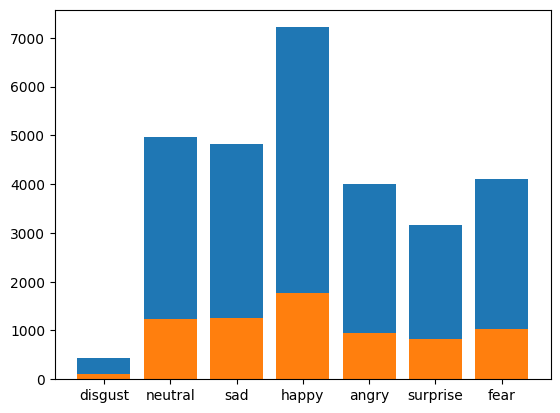

In [ ]:
plt.bar(df_train.columns,df_train.iloc[0])
plt.bar(df_test.columns,df_test.iloc[0])
plt.show()

[link text](https:// [link text](https:// [link text](https://)))Plotting a single image from each emotion

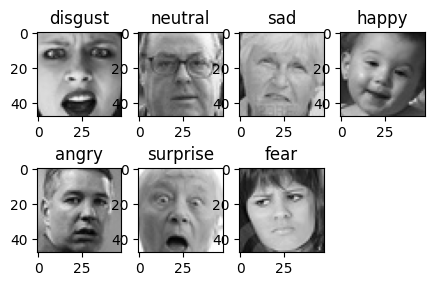

In [ ]:
# @title
train_dir = '/content/train'
plt.figure(figsize=(5,5))
for dir_path,folders,files in os.walk(train_dir):
  for i,folder in enumerate(folders):
    r=random.choice(os.listdir(os.path.join(dir_path,folder)))
    img = load_img(os.path.join(dir_path,folder)+'/'+r)
    plt.subplot(3,4,i+1)
    plt.imshow(img)
    plt.title(folder)

plt.show()

(48, 48, 1)


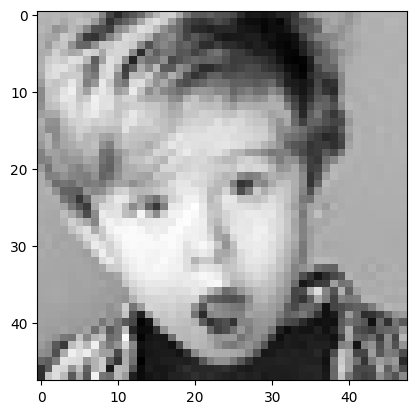

In [ ]:
img = load_img('/content/train/surprise/Training_10028230.jpg',target_size=(48,48),color_mode='grayscale')
print(img_to_array(img).shape)
plt.imshow(img,cmap='gray')
plt.show()
# the target_size attribute of load_image just redivides the image into given number of pixels
# if you want to make the image appear bigger then use figsize as shown above
# Also notice that by default load_img loads the images in RGB i.e. 3 channels but we know we have grayscale images
# so load the images in grayscale to avoid duplication of values



```
# This is formatted as code
```

# Model 1: Custom CNN from Scratch

Initialising the Image Generators

In [ ]:
num_classes= 7
test_dir = '/content/test'
train_dir = '/content/train'
img_width,img_height = 48,48
batch_size = 64
epochs = 10

In [ ]:
data_gen = ImageDataGenerator(rescale=1/255,validation_split=0.2)

In [ ]:
train_generator=data_gen.flow_from_directory(
    train_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    color_mode='grayscale'
)
validation_generator=data_gen.flow_from_directory(
    train_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    color_mode='grayscale'
)
test_generator = data_gen.flow_from_directory(
    test_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale'
)

Found 22968 images belonging to 7 classes.
Found 5741 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [ ]:
train_class_labels = train_generator.class_indices
print(train_class_labels)
test_class_labels = test_generator.class_indices
print(test_class_labels)
validation_class_labels = validation_generator.class_indices
print(validation_class_labels)

{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [ ]:
# Batch normalization helps prevent overfitting and speeds up training of deep neural networks
# It normalizes activations of each layer by subtracting mean and dividing by standard deviation
# Rescaling and offsetting is done using learnable parameters gamma and beta
# Batch normalization handles internal covariate shift and smoothens the loss landscape
# Dropout makes 25% of the values randomly to 0
# This we do to avoid duplicate information

model = Sequential()
model.add(Input(shape=(img_width, img_height, 1)))

model.add(Conv2D(
    32,
    kernel_size=(3, 3),
    kernel_initializer="glorot_uniform",
    padding='same'
))
model.add(Activation('relu'))
model.add(Conv2D(64, kernel_size=(3, 3), padding='same'))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2, 2))
model.add(Dropout(0.25))

model.add(Conv2D(128, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(Activation('relu'))
model.add(Conv2D(256, kernel_size=(3, 3), kernel_regularizer=regularizers.l2(0.01)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(512, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(Activation('relu'))
model.add(Conv2D(512, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(1024))
model.add(Activation('relu'))
model.add(Dropout(0.5))

model.add(Dense(num_classes))
model.add(Activation('softmax'))

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

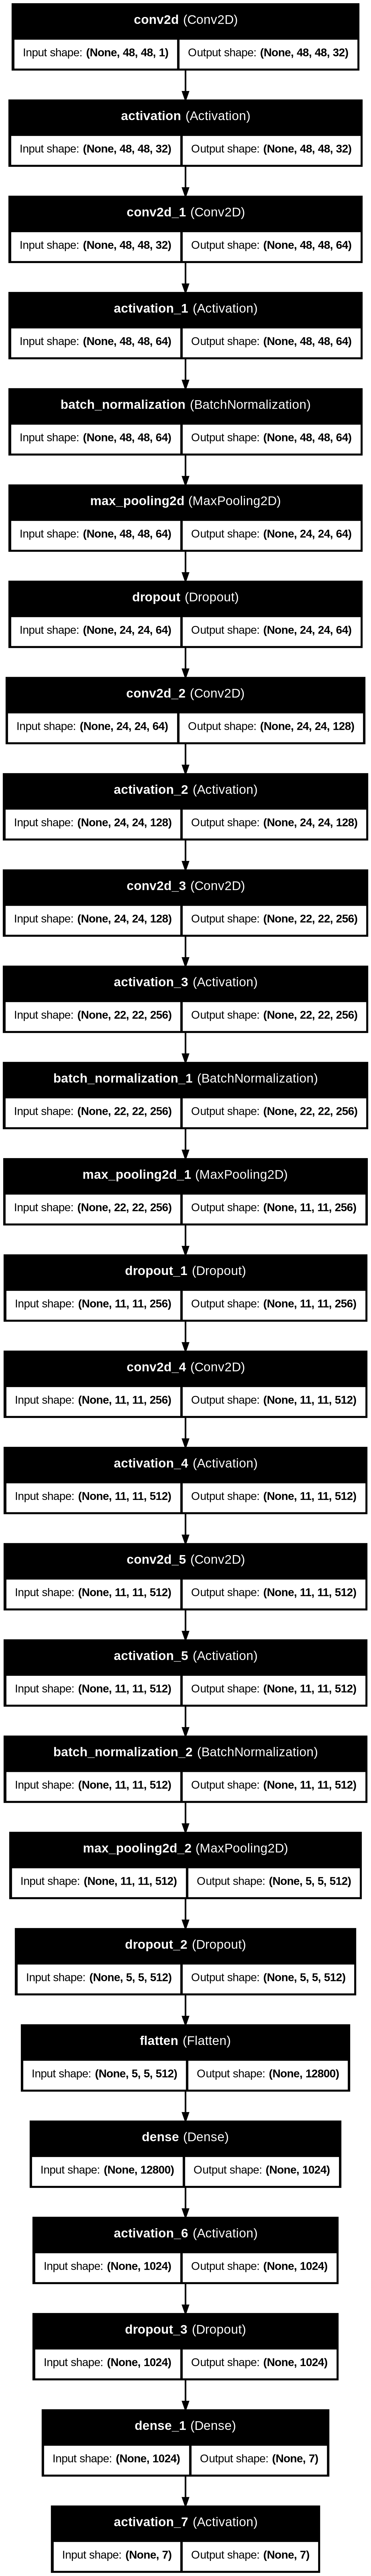

In [ ]:
plot_model(model, to_file='/content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Architecture.png', show_shapes=True,show_layer_names=True)

# Understanding Callbacks

In [ ]:
# File path for the model checkpoint
cnn_path = '/content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch'
name = 'Custom_CNN_model.keras'
chk_path = os.path.join(cnn_path, name)
chk_path

'/content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Custom_CNN_model.keras'

In [ ]:
# Callback to save the model checkpoint
# verbose is basically it will output the update msgs when set to 1 else it operates in quiet mode
# when val_loss decreases it saves that checkpoint
checkpoint = ModelCheckpoint(filepath=chk_path,
                             save_best_only=True,
                             verbose=1,
                             mode='min',
                             monitor='val_loss')

In [ ]:
# Callback for early stopping
# min_delta is that the validation loss should decrease atleast by 0
# if it does not decrease or increase for patience number of epochs then training is stopped
# and best weights are restored
earlystop = EarlyStopping(monitor='val_loss',
                          min_delta=0,
                          patience=3,
                          verbose=1,
                          restore_best_weights=True)

In [ ]:
# Callback to reduce learning rate
# Reduce learning rate when val_loss is not improving by atleast min_delta amount
# for patience number of epochs
reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=6,
                              verbose=1,
                              min_delta=0.0001)

In [ ]:
# Callback to log training data to a CSV file
csv_logger = CSVLogger(os.path.join(cnn_path,'training.log'))

In [ ]:
# Aggregating all callbacks into a list
callbacks = [checkpoint, earlystop, reduce_lr, csv_logger]  # Adjusted as per your use-case

# Calculating Steps for Epoch

In [ ]:
train_generator.samples

22968

In [ ]:
train_steps_per_epoch = train_generator.samples // train_generator.batch_size + 1
print(train_steps_per_epoch)
validation_steps_per_epoch = validation_generator.samples // validation_generator.batch_size + 1
print(validation_steps_per_epoch)
test_steps_per_epoch = test_generator.samples // test_generator.batch_size + 1
print(test_steps_per_epoch)

359
90
113


# Training

In [ ]:
train_generator.reset()
history = model.fit(
    train_generator,
    steps_per_epoch=train_steps_per_epoch,
    epochs=10,
    validation_data=validation_generator,
    validation_steps=validation_steps_per_epoch,
    callbacks=callbacks
)

Epoch 1/10
358/359 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.2494 - loss: 13.3460
Epoch 1: val_loss improved from None to 16.90966, saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Custom_CNN_model.keras

Epoch 1: finished saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Custom_CNN_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 88s 154ms/step - accuracy: 0.2818 - loss: 12.3960 - val_accuracy: 0.1427 - val_loss: 16.9097 - learning_rate: 1.0000e-04
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3312 - loss: 10.7069
Epoch 2: val_loss improved from 16.90966 to 9.66667, saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Custom_CNN_model.keras

Epoch 2: finished saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_From_Scratch/Custom_CNN_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.3513 - loss: 10.1831 - val_accuracy: 0.3743 - val_loss: 9.6667 - learning_rate:

# Plotting performance metrics

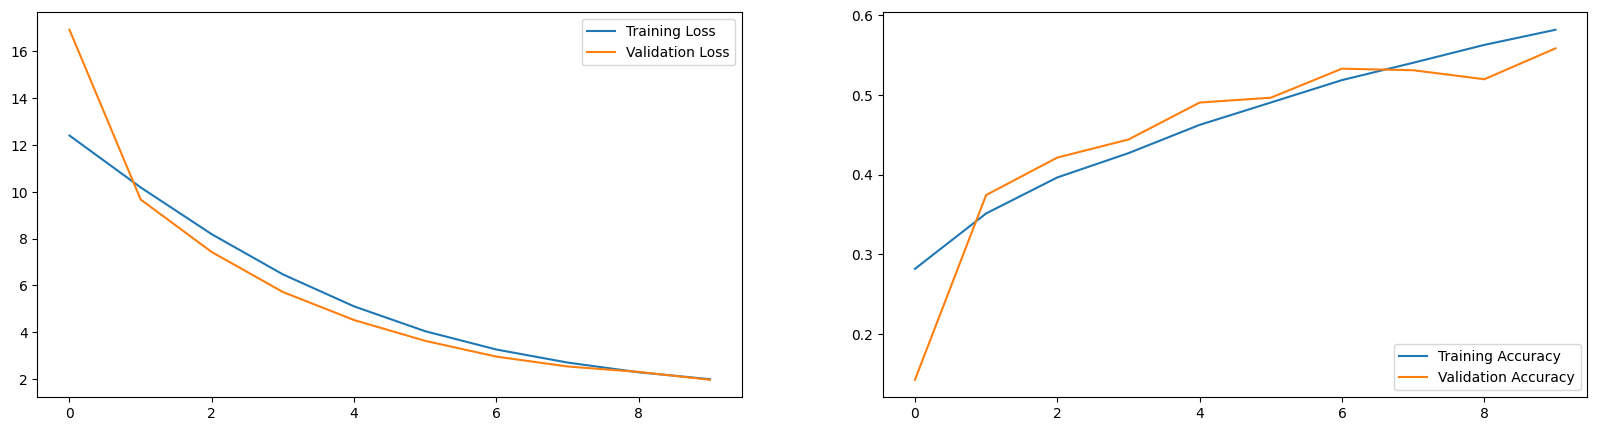

In [ ]:
train_loss=history.history['loss']
train_acc=history.history['accuracy']
val_loss=history.history['val_loss']
val_acc=history.history['val_accuracy']
epoch_range = np.arange(epochs)

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(epoch_range,train_loss,label='Training Loss')
plt.plot(epoch_range,val_loss,label='Validation Loss')
plt.legend(loc='upper right')

plt.subplot(1,2,2)
plt.plot(epoch_range,train_acc,label='Training Accuracy')
plt.plot(epoch_range,val_acc,label='Validation Accuracy')
plt.legend(loc='lower right')

plt.show()

In [ ]:
train_loss, train_accu = model.evaluate(train_generator)
test_loss, test_accu = model.evaluate(test_generator)
print("final train accuracy = {:.2f} , validation accuracy = {:.2f}".format(train_accu*100, test_accu*100))

359/359 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.6487 - loss: 1.7570
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.5573 - loss: 1.9732
final train accuracy = 64.87 , validation accuracy = 55.73


In [ ]:
true_classes = test_generator.classes
predicted_classes = model.predict(test_generator)
print(predicted_classes.shape)


113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step
(7178, 7)


In [ ]:
predicted_classes= np.argmax(predicted_classes, axis=1)
cm = confusion_matrix(true_classes, predicted_classes)
print(cm)

[[119   2 124 241 147 159 166]
 [ 15   0  12  20  19  16  29]
 [117   4 136 247 171 172 177]
 [225   7 225 387 284 309 337]
 [158   5 159 277 196 227 211]
 [156   2 172 298 196 218 205]
 [100   5  96 196 123 153 158]]


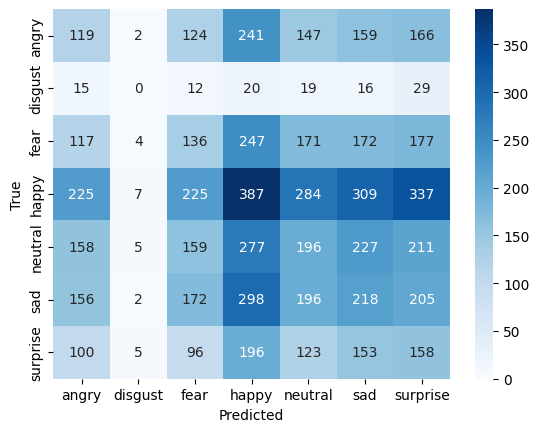

In [ ]:
class_labels = test_generator.class_indices
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=class_labels.keys(),yticklabels=class_labels.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
# We can see model is performing very bad due to class imbalance
# maybe architecture is not good
# So we will use pre trained models in the next section

In [ ]:
report=classification_report(true_classes, predicted_classes,target_names=class_labels.keys())
print(report)

              precision    recall  f1-score   support

       angry       0.13      0.12      0.13       958
     disgust       0.00      0.00      0.00       111
        fear       0.15      0.13      0.14      1024
       happy       0.23      0.22      0.23      1774
     neutral       0.17      0.16      0.17      1233
         sad       0.17      0.17      0.17      1247
    surprise       0.12      0.19      0.15       831

    accuracy                           0.17      7178
   macro avg       0.14      0.14      0.14      7178
weighted avg       0.17      0.17      0.17      7178



In [ ]:
print(len(test_generator))
print(true_classes.shape)

113
(7178,)


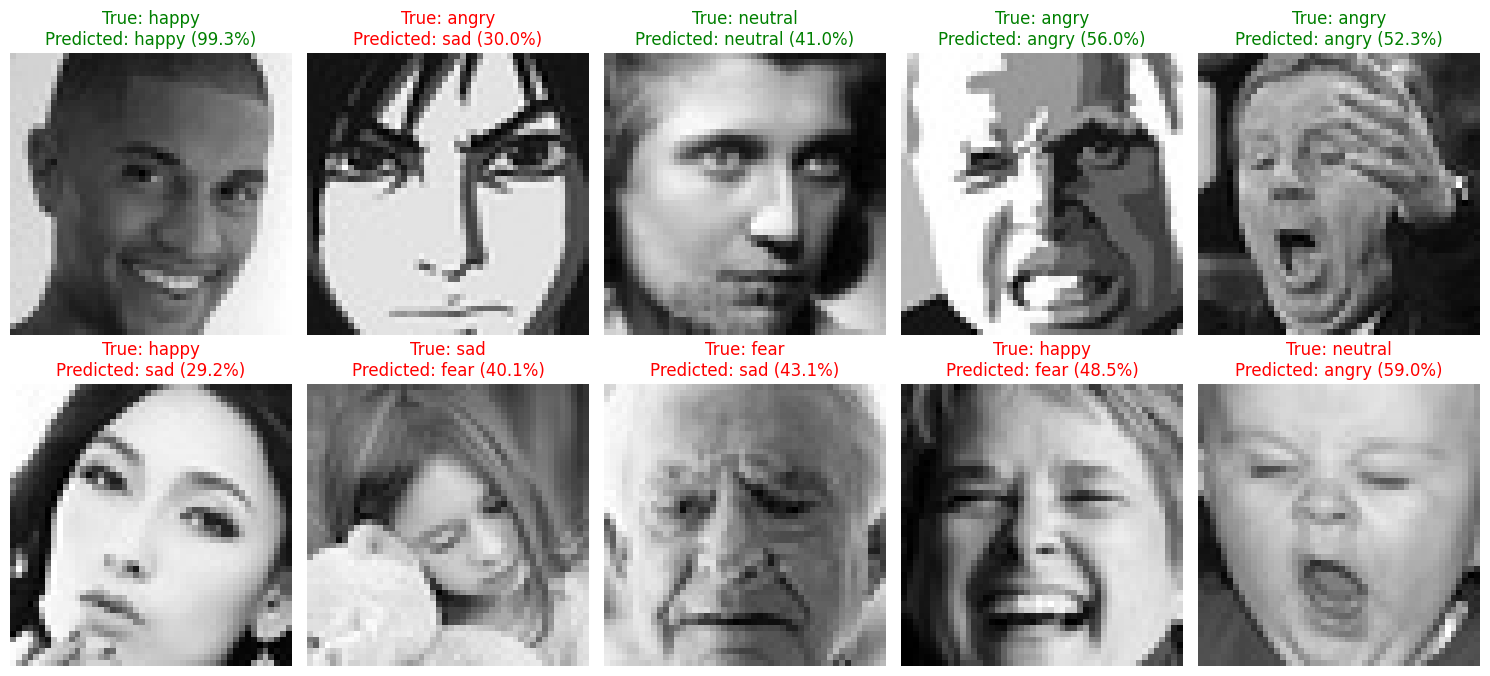

In [ ]:

import random
import numpy as np
import matplotlib.pyplot as plt

# Get emotion names in the correct class-index order
Emotion_classes = [
    name for name, index in sorted(
        test_generator.class_indices.items(),
        key=lambda item: item[1]
    )
]

# Select one batch
Random_batch = random.randrange(len(test_generator))
images, labels = test_generator[Random_batch]

# Predict on these exact images
predictions = model.predict(images, verbose=0)

# Get true and predicted class indices
true_indices = np.argmax(labels, axis=1)
predicted_indices = np.argmax(predictions, axis=1)

# Choose up to 10 DIFFERENT images from this batch
Random_img_indices = random.sample(
    range(len(images)),
    min(10, len(images))
)

fig, ax = plt.subplots(2, 5, figsize=(15, 7))
ax = ax.ravel()

for i, idx in enumerate(Random_img_indices):
    True_label = Emotion_classes[true_indices[idx]]
    Predicted_label = Emotion_classes[predicted_indices[idx]]

    ax[i].imshow(images[idx].squeeze(), cmap='gray')

    color = 'green' if True_label == Predicted_label else 'red'

    confidence = predictions[idx][predicted_indices[idx]] * 100

    ax[i].set_title(
        f"True: {True_label}\n"
        f"Predicted: {Predicted_label} ({confidence:.1f}%)",
        color=color
    )
    ax[i].axis('off')

plt.tight_layout()
plt.show()


# Image Augmentation


In [ ]:
train_dir = '/content/train'
test_dir = '/content/test'

epochs=10
num_classes=7
img_width,img_height = 48,48
batch_size = 64

# Initializing the ImageDataGenerator with data augmentation options for the training set
data_generator = ImageDataGenerator(
    rescale=1/255,  # Rescale the pixel values from [0, 255] to [0, 1]
    rotation_range=40,  # Degree range for random rotations
    width_shift_range=0.2,  # Range (as a fraction of total width) for random horizontal shifts
    height_shift_range=0.2,  # Range (as a fraction of total height) for random vertical shifts
    shear_range=0.2,  # Shearing intensity (shear angle in counter-clockwise direction)
    zoom_range=0.2,  # Range for random zoom
    horizontal_flip=True,  # Randomly flip inputs horizontally
    fill_mode='nearest',  # Strategy to fill newly created pixels, which can appear after a rotation or a width/height shift
    validation_split=0.2  # Set the validation split; 20% of the data will be used for validation
)

test_data_generator = ImageDataGenerator(rescale=1/255)

train_generator = data_generator.flow_from_directory(
    train_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale',
    subset='training')

validation_generator = data_generator.flow_from_directory(
    train_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale',
    subset='validation')

test_generator = test_data_generator.flow_from_directory(
    test_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale'
    )

Found 22968 images belonging to 7 classes.
Found 5741 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


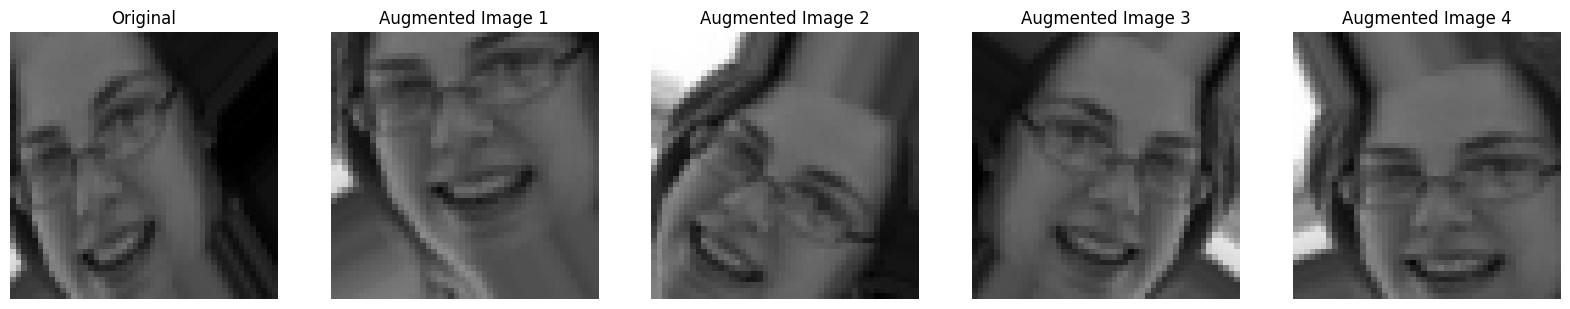

In [ ]:
image_path = '/content/train/happy/Training_10019449.jpg'
img_array = load_img(image_path)
img_array = img_to_array(img_array)
img_array = np.expand_dims(img_array, axis=0)


fig,ax = plt.subplots(1,5,figsize=(20,5))
ax=ax.flatten()

aug_iter=data_generator.flow(img_array)
for i in range(5):
  img=next(aug_iter)[0]
  ax[i].imshow(img,cmap='gray')
  ax[i].axis('off')
  title = 'Original' if i==0 else f'Augmented Image {i}'
  ax[i].set_title(title)
plt.show()

#This is how augmented images will be added to provide more data artificially while flowing/training

In [ ]:
# Assuming img_width, img_height, and classes are defined. For example:
img_width, img_height = 48, 48
classes = 7

#Initialising the CNN
model = tf.keras.models.Sequential()

# Adding convolutional layers with activations on separate lines
model.add(Conv2D(32, kernel_size=(3, 3), padding='same', input_shape=(img_width, img_height, 1)))
model.add(tf.keras.layers.Activation('relu'))
model.add(Conv2D(64, kernel_size=(3, 3), padding='same'))
model.add(tf.keras.layers.Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2, 2))
model.add(Dropout(0.25))

model.add(Conv2D(128, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(tf.keras.layers.Activation('relu'))
model.add(Conv2D(256, kernel_size=(3, 3), kernel_regularizer=regularizers.l2(0.01)))
model.add(tf.keras.layers.Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(512, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(tf.keras.layers.Activation('relu'))
model.add(Conv2D(512, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(0.01)))
model.add(tf.keras.layers.Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Flattening and adding dense layers
model.add(Flatten())
model.add(Dense(1024))
model.add(tf.keras.layers.Activation('relu'))
model.add(Dropout(0.5))

model.add(Dense(classes))
model.add(tf.keras.layers.Activation('softmax'))

# Compiling the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


# File path for the model checkpoint
cnn_path = '/content/FER_2013_Emotion_Detection/Custom_CNN_With_Augmentation'
name = 'Custom_CNN_augmented_model.keras'
chk_path = os.path.join(cnn_path, name)

# Callback to save the model checkpoint
checkpoint = ModelCheckpoint(filepath=chk_path,
                             save_best_only=True,
                             verbose=1,
                             mode='min',
                             monitor='val_loss')

# Callback for early stopping
earlystop = EarlyStopping(monitor='val_loss',
                          min_delta=0,
                          patience=3,
                          verbose=1,
                          restore_best_weights=True)

# Callback to reduce learning rate
reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=6,
                              verbose=1,
                              min_delta=0.0001)

# Callback to log training data to a CSV file
csv_logger = CSVLogger(os.path.join(cnn_path,'training.log'))

# Aggregating all callbacks into a list
callbacks = [checkpoint, earlystop, reduce_lr, csv_logger]  # Adjusted as per your use-case

train_steps_per_epoch = train_generator.samples // train_generator.batch_size + 1
validation_steps_epoch = validation_generator.samples // validation_generator.batch_size + 1
test_steps_epoch = test_generator.samples // test_generator.batch_size + 1

history = model.fit(
    train_generator,
    steps_per_epoch=train_steps_per_epoch,
    epochs=10,
    validation_data=validation_generator,
    validation_steps=validation_steps_epoch,
    callbacks=callbacks)

# If I want to reset the weights then I have to create a new instance mere compiling again would not help

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.2037 - loss: 13.3622
Epoch 1: val_loss improved from None to 12.30149, saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_With_Augmentation/Custom_CNN_augmented_model.keras

Epoch 1: finished saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_With_Augmentation/Custom_CNN_augmented_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 53s 118ms/step - accuracy: 0.2185 - loss: 12.4686 - val_accuracy: 0.1430 - val_loss: 12.3015 - learning_rate: 1.0000e-04
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.2372 - loss: 10.7720
Epoch 2: val_loss improved from 12.30149 to 9.76424, saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_With_Augmentation/Custom_CNN_augmented_model.keras

Epoch 2: finished saving model to /content/FER_2013_Emotion_Detection/Custom_CNN_With_Augmentation/Custom_CNN_augmented_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 31s 87ms/step - accuracy: 0.2382 - loss: 10.2368

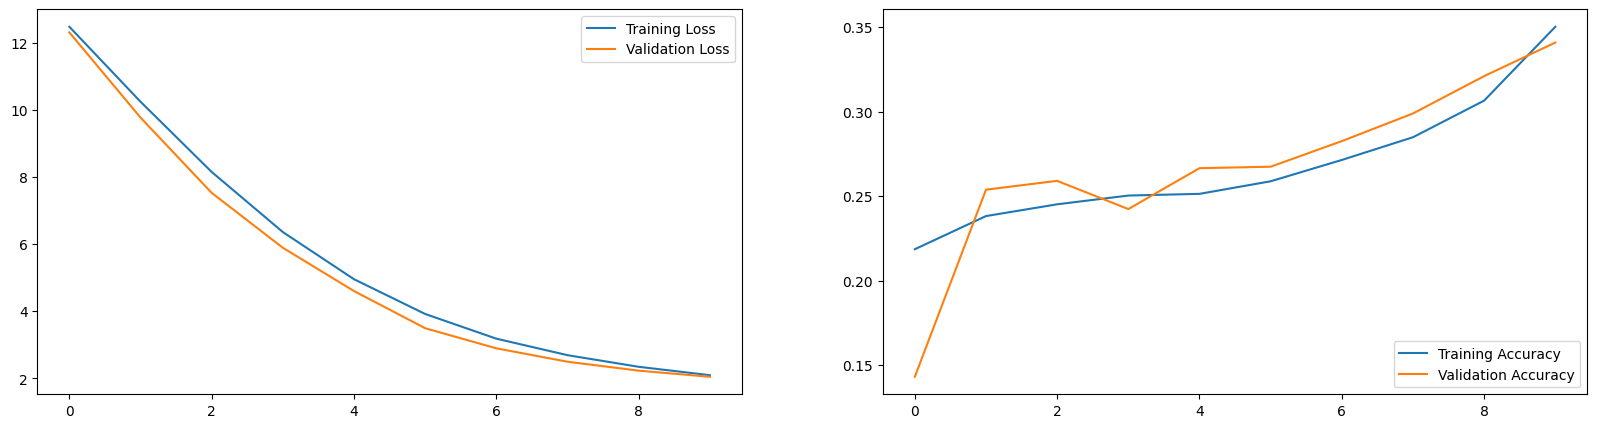

In [ ]:
train_loss=history.history['loss']
train_acc=history.history['accuracy']
val_loss=history.history['val_loss']
val_acc=history.history['val_accuracy']
epoch_range = np.arange(epochs)

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(epoch_range,train_loss,label='Training Loss')
plt.plot(epoch_range,val_loss,label='Validation Loss')
plt.legend(loc='upper right')

plt.subplot(1,2,2)
plt.plot(epoch_range,train_acc,label='Training Accuracy')
plt.plot(epoch_range,val_acc,label='Validation Accuracy')
plt.legend(loc='lower right')

plt.show()

In [ ]:
train_loss, train_accu = model.evaluate(train_generator)
test_loss, test_accu = model.evaluate(test_generator)
print("final train accuracy = {:.2f} , validation accuracy = {:.2f}".format(train_accu*100, test_accu*100))

359/359 ━━━━━━━━━━━━━━━━━━━━ 24s 67ms/step - accuracy: 0.3386 - loss: 2.0506
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3537 - loss: 2.0393
final train accuracy = 33.86 , validation accuracy = 35.37


In [ ]:
true_classes = test_generator.classes
predicted_classes = model.predict(test_generator)
print(predicted_classes.shape)


113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step
(7178, 7)


In [ ]:
predicted_classes= np.argmax(predicted_classes, axis=1)
cm = confusion_matrix(true_classes, predicted_classes)
print(cm)

[[  0   0  38 258 219  32 411]
 [  0   0   3  28  25   3  52]
 [  1   0  37 257 247  38 444]
 [  0   0  62 437 405  52 818]
 [  0   0  48 304 289  31 561]
 [  0   0  38 312 308  49 540]
 [  0   0  31 210 191  30 369]]


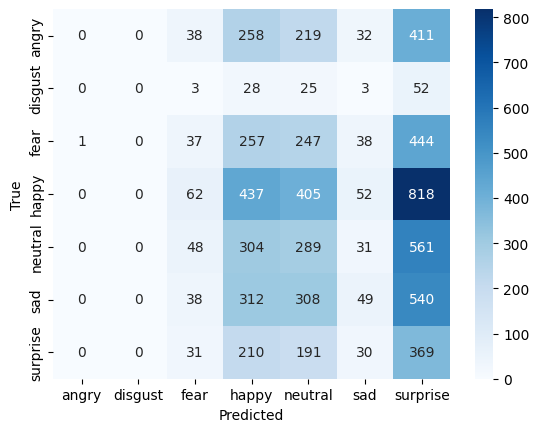

In [ ]:
class_labels = test_generator.class_indices
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=class_labels.keys(),yticklabels=class_labels.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
# We can see model is performing very bad due to class imbalance
# maybe architecture is not good
# So we will use pre trained models in the next section

In [ ]:
report=classification_report(true_classes, predicted_classes,target_names=class_labels.keys())
print(report)

              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       958
     disgust       0.00      0.00      0.00       111
        fear       0.14      0.04      0.06      1024
       happy       0.24      0.25      0.24      1774
     neutral       0.17      0.23      0.20      1233
         sad       0.21      0.04      0.07      1247
    surprise       0.12      0.44      0.18       831

    accuracy                           0.16      7178
   macro avg       0.13      0.14      0.11      7178
weighted avg       0.16      0.16      0.14      7178



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Transfer Learning using VGGNet

In [ ]:
train_dir = '/content/train'
test_dir = '/content/test'
img_width,img_height=224,224
# as of ImageNet dataset
num_classes=7
batch_size=64
epochs=10

data_generator=ImageDataGenerator(
    rescale=1/255,
    rotation_range=10,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
)

test_data_generator=ImageDataGenerator(rescale=1/255)

train_generator = data_generator.flow_from_directory(
    train_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb',
    shuffle=True,
    subset='training'
)

test_generator = test_data_generator.flow_from_directory(
    test_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb'
)

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [ ]:
classes = np.array(train_generator.classes)

class_weights=compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)
class_weights=dict(enumerate(class_weights))
class_weights

# observe that disgust(1) class has the maximum weight because it has very less images
# and happy(3) has the least weight because it has most images
# Higher weight means on making a mistake in that classes it will be corrected more aggressively

{0: np.float64(1.0266046844269623),
 1: np.float64(9.406618610747051),
 2: np.float64(1.0010460615781582),
 3: np.float64(0.5684387684387684),
 4: np.float64(0.8260394187886635),
 5: np.float64(0.8491274770777877),
 6: np.float64(1.293372978330405)}

In [ ]:
train_generator.class_indices

{'angry': 0,
 'disgust': 1,
 'fear': 2,
 'happy': 3,
 'neutral': 4,
 'sad': 5,
 'surprise': 6}

In [ ]:
tf.keras.backend.clear_session()

vgg = VGG16(
    include_top=False,
    weights='imagenet',
    input_shape=(img_width,img_height,3)
)

# include_top = False means we don't want to include the dense layers just the convolution layers
vgg.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

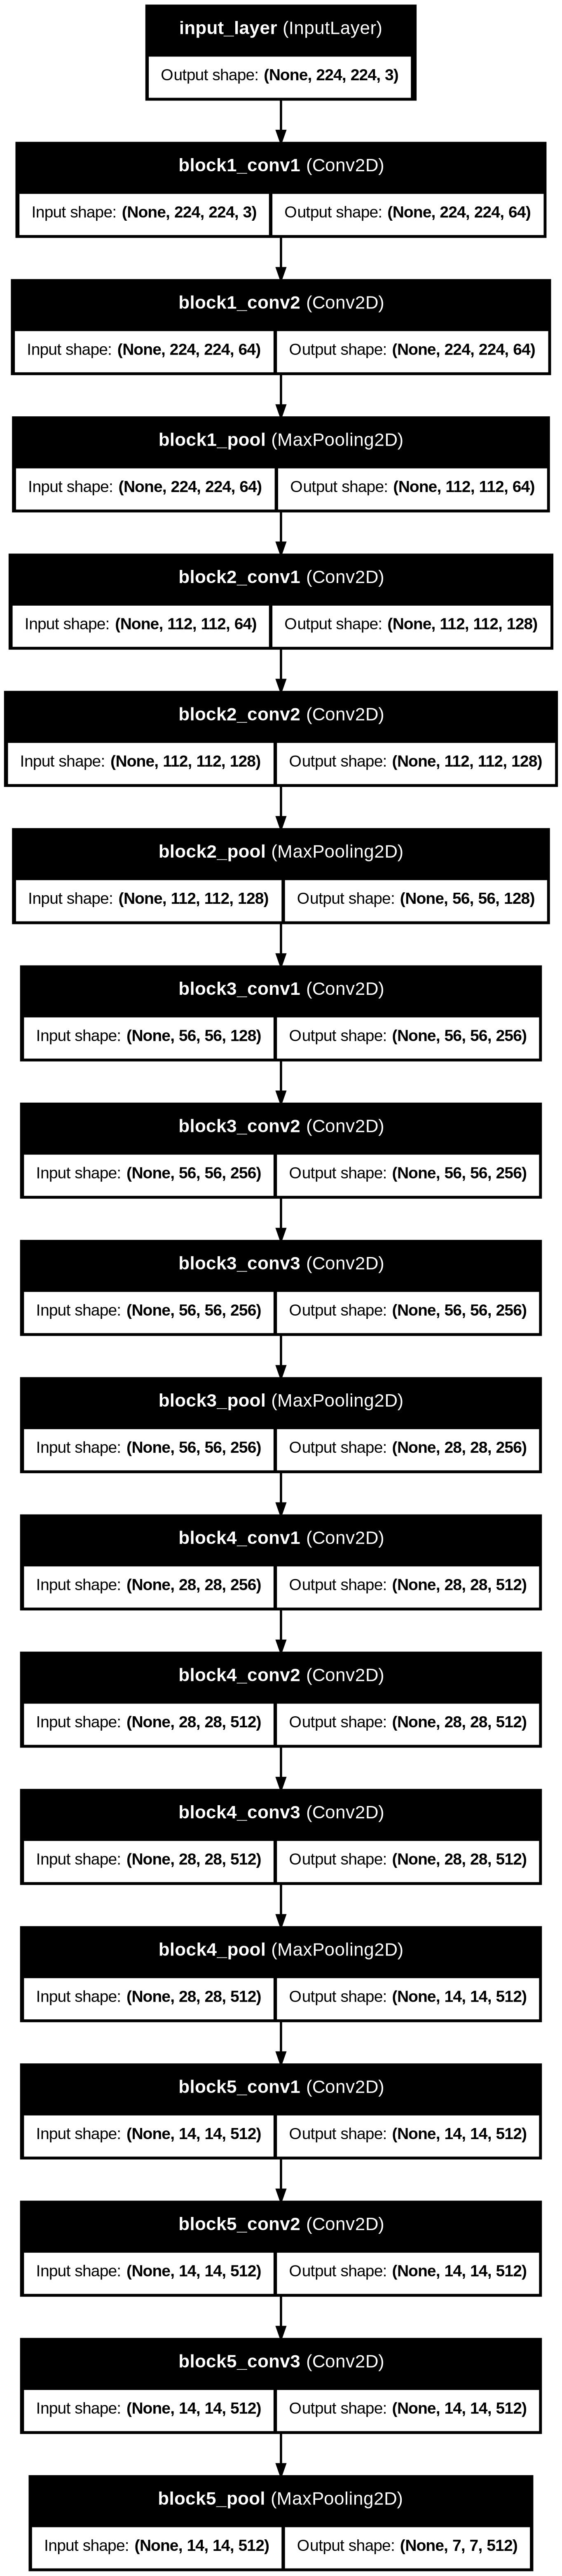

In [ ]:
plot_model(vgg,show_shapes=True,show_layer_names=True)

In [ ]:
for layer in vgg.layers[-4:]:
  print(layer.name)

block5_conv1
block5_conv2
block5_conv3
block5_pool


In [ ]:
for layer in vgg.layers[:-3]:
  layer.trainable=False

vgg.summary()
# observe that the trainable parameters only include block5_conv2 and block5_conv3
# We discussed that we will retrain some of the last layers to fit our use case

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 4,719,616 (18.00 MB)

 Non-trainable params: 9,995,072 (38.13 MB)

In [ ]:
x = Flatten()(vgg.output)

x = Dense(1024, activation='relu',kernel_initializer='he_normal')(x)
x = Dropout(0.5)(x)

x = Dense(512, activation='relu',kernel_initializer='he_normal')(x)
x = Dropout(0.5)(x)

x = Dense(num_classes, activation='softmax',kernel_initializer='he_normal')(x)

model = Model(inputs=vgg.input, outputs=x)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001,beta_1=0.9,beta_2=0.999,amsgrad=False),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │    25,691,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         3,59

 Total params: 40,934,215 (156.15 MB)

 Trainable params: 30,939,143 (118.02 MB)

 Non-trainable params: 9,995,072 (38.13 MB)

In [ ]:
# File path for the model checkpoint
cnn_path = '/content/FER_2013_Emotion_Detection/VGG16_Transfer_Learning'
name = 'VGG16_Transfer_Learning.keras'
chk_path = os.path.join(cnn_path, name)

# Callback to save the model checkpoint
checkpoint = ModelCheckpoint(filepath=chk_path,
                             save_best_only=True,
                             verbose=1,
                             mode='min',
                             monitor='val_loss')

# Callback for early stopping
earlystop = EarlyStopping(monitor='val_loss',
                          min_delta=0,
                          patience=3,
                          verbose=1,
                          restore_best_weights=True)

# Callback to reduce learning rate
reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=6,
                              verbose=1,
                              min_delta=0.0001)

# Callback to log training data to a CSV file
csv_logger = CSVLogger(os.path.join(cnn_path,'training.log'))

# Aggregating all callbacks into a list
callbacks = [checkpoint, earlystop, reduce_lr, csv_logger]  # Adjusted as per your use-case

train_steps_per_epoch = train_generator.samples // train_generator.batch_size + 1
# validation_steps_epoch = validation_generator.samples // validation_generator.batch_size + 1
test_steps_epoch = test_generator.samples // test_generator.batch_size + 1

In [61]:
history = model.fit(
    train_generator,
    steps_per_epoch=train_steps_per_epoch,
    epochs=10,
    batch_size=batch_size,
    callbacks=callbacks,
    class_weight=class_weights,
    validation_data=test_generator,
    validation_steps=test_steps_epoch
)

Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2055 - loss: 1.9903
Epoch 1: val_loss improved from None to 1.61990, saving model to /content/FER_2013_Emotion_Detection/VGG16_Transfer_Learning/VGG16_Transfer_Learning.keras

Epoch 1: finished saving model to /content/FER_2013_Emotion_Detection/VGG16_Transfer_Learning/VGG16_Transfer_Learning.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 591s 1s/step - accuracy: 0.2477 - loss: 1.8576 - val_accuracy: 0.3674 - val_loss: 1.6199 - learning_rate: 1.0000e-04
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3466 - loss: 1.6674
Epoch 2: val_loss improved from 1.61990 to 1.50904, saving model to /content/FER_2013_Emotion_Detection/VGG16_Transfer_Learning/VGG16_Transfer_Learning.keras

Epoch 2: finished saving model to /content/FER_2013_Emotion_Detection/VGG16_Transfer_Learning/VGG16_Transfer_Learning.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 535s 1s/step - accuracy: 0.3745 - loss: 1.6173 - val_accuracy: 0.4110 - val_loss: 1.5090 - l

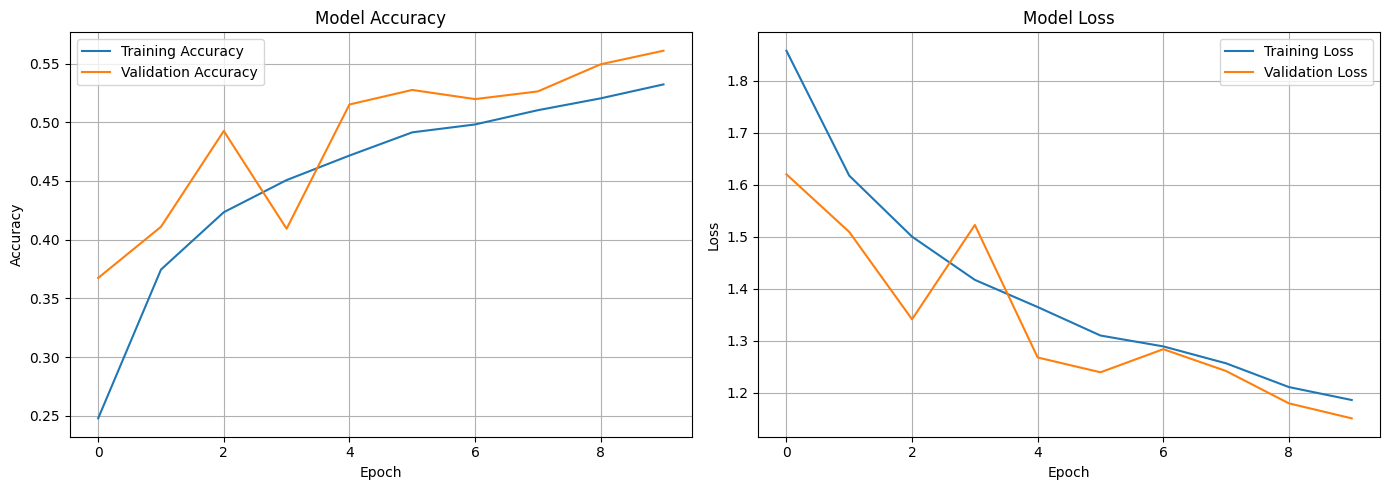

In [62]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    acc = history.history.get('accuracy', history.history.get('acc'))
    val_acc = history.history.get('val_accuracy', history.history.get('val_acc'))
    loss = history.history.get('loss')
    val_loss = history.history.get('val_loss')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    if acc is not None:
        axes[0].plot(acc, label='Training Accuracy')
    if val_acc is not None:
        axes[0].plot(val_acc, label='Validation Accuracy')
    axes[0].set_title('Model Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True)

    if loss is not None:
        axes[1].plot(loss, label='Training Loss')
    if val_loss is not None:
        axes[1].plot(val_loss, label='Validation Loss')
    axes[1].set_title('Model Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_training_history(history)

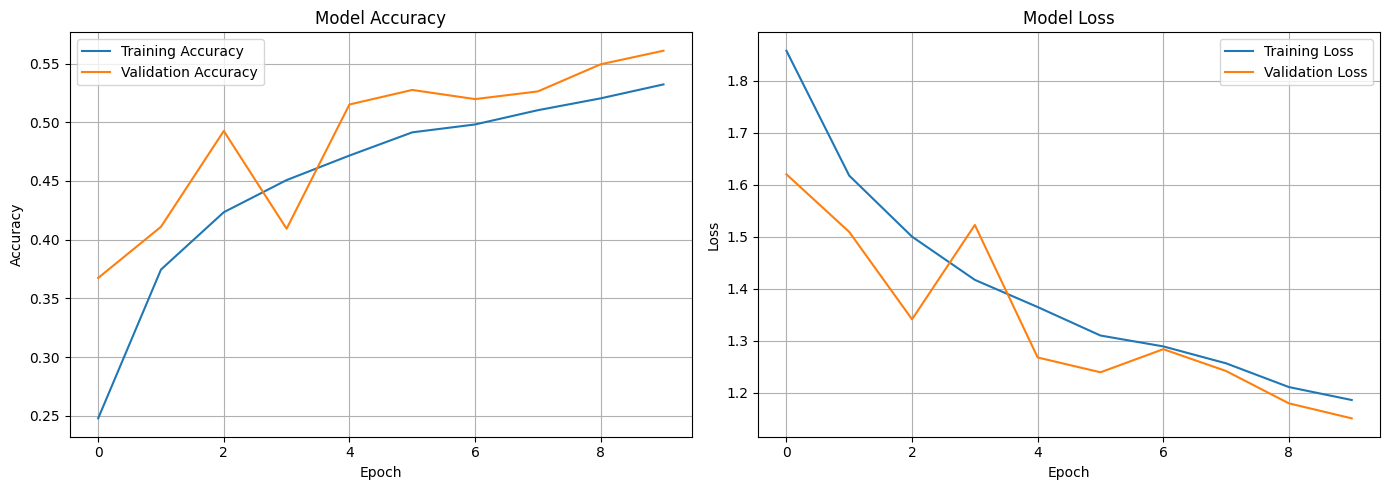

In [63]:
plot_training_history(history)

In [64]:
train_loss, train_accu = model.evaluate(train_generator)
test_loss, test_accu = model.evaluate(test_generator)
print("final train accuracy = {:.2f} , validation accuracy = {:.2f}".format(train_accu*100, test_accu*100))

449/449 ━━━━━━━━━━━━━━━━━━━━ 445s 991ms/step - accuracy: 0.5636 - loss: 1.1394
113/113 ━━━━━━━━━━━━━━━━━━━━ 36s 318ms/step - accuracy: 0.5610 - loss: 1.1504
final train accuracy = 56.36 , validation accuracy = 56.10


In [ ]:
import numpy as np

test_generator.reset()

# Predict one batch at a time, including the final incomplete batch
all_predictions = []

for i in range(len(test_generator)):
    images, labels = test_generator[i]
    batch_predictions = model.predict(images, verbose=0)
    all_predictions.extend(np.argmax(batch_predictions, axis=1))

predicted_classes = np.array(all_predictions)
true_classes = test_generator.classes

print("True labels:", len(true_classes))
print("Predictions:", len(predicted_classes))

In [ ]:
# Assuming your true_classes and predicted_classes are already defined
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class_labels = list(test_generator.class_indices.keys())

# Generate the confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plotting with seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
# Printing the classification report
report = classification_report(true_classes,
                               predicted_classes,
                               target_names=class_labels,
                               zero_division=0)
print("Classification Report:\n", report)

# Transfer Learning using ResNet50

In [68]:
train_dir = '/content/train'
test_dir = '/content/test'
img_width,img_height=224,224
# as of ImageNet dataset
num_classes=7
batch_size=64
epochs=10

data_generator=ImageDataGenerator(
    rescale=1/255,
    rotation_range=10,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
)

test_data_generator=ImageDataGenerator(rescale=1/255)

train_generator = data_generator.flow_from_directory(
    train_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb',
    shuffle=True,
    subset='training'
)

test_generator = test_data_generator.flow_from_directory(
    test_dir,
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb'
)

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [ ]:
classes = np.array(train_generator.classes)

class_weights=compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)
class_weights=dict(enumerate(class_weights))
class_weights

# observe that disgust(1) class has the maximum weight because it has very less images
# and happy(3) has the least weight because it has most images
# Higher weight means on making a mistake in that classes it will be corrected more aggressively

In [70]:
ResNet50V2 = tf.keras.applications.ResNet50V2(
    include_top=False,
    weights='imagenet',
    input_shape=(224,224,3)
)

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [71]:
len(ResNet50V2.layers)

190

In [72]:
len(vgg.layers)

19

In [73]:
ResNet50V2.trainable=True

for layer in ResNet50V2.layers[:-50]:
  layer.trainable=False

# Only the last 50 layers will be trainable

In [74]:
model = Sequential([
    ResNet50V2,
    Dropout(0.25),
    BatchNormalization(),
    Flatten(),
    Dense(64,activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(7,activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 2048)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 2048)     │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │     6,422,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,996,295 (114.43 MB)

 Trainable params: 22,779,527 (86.90 MB)

 Non-trainable params: 7,216,768 (27.53 MB)

In [75]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [76]:
# File path for the model checkpoint
cnn_path = '/content/FER_2013_Emotion_Detection/ResNet50_Transfer_Learning'
name = 'ResNet50_Transfer_Learning.keras'
chk_path = os.path.join(cnn_path, name)

# Callback to save the model checkpoint
checkpoint = ModelCheckpoint(filepath=chk_path,
                             save_best_only=True,
                             verbose=1,
                             mode='min',
                             monitor='val_loss')

# Callback for early stopping
earlystop = EarlyStopping(monitor='val_loss',
                          min_delta=0,
                          patience=3,
                          verbose=1,
                          restore_best_weights=True)

# Callback to reduce learning rate
reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                              factor=0.2,
                              patience=6,
                              verbose=1,
                              min_delta=0.0001)

# Callback to log training data to a CSV file
csv_logger = CSVLogger(os.path.join(cnn_path,'training.log'))

# Aggregating all callbacks into a list
callbacks = [checkpoint, earlystop, reduce_lr, csv_logger]  # Adjusted as per your use-case

train_steps_per_epoch = train_generator.samples // train_generator.batch_size + 1
# validation_steps_epoch = validation_generator.samples // validation_generator.batch_size + 1
test_steps_epoch = test_generator.samples // test_generator.batch_size + 1

In [77]:
train_history = model.fit(
    train_generator,
    batch_size=batch_size,
    epochs=30,
    steps_per_epoch=train_steps_per_epoch,
    validation_data=test_generator,
    validation_steps=test_steps_epoch,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3140 - loss: 2.0393
Epoch 1: val_loss improved from None to 3.35825, saving model to /content/FER_2013_Emotion_Detection/ResNet50_Transfer_Learning/ResNet50_Transfer_Learning.keras

Epoch 1: finished saving model to /content/FER_2013_Emotion_Detection/ResNet50_Transfer_Learning/ResNet50_Transfer_Learning.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 580s 1s/step - accuracy: 0.3740 - loss: 1.8154 - val_accuracy: 0.4191 - val_loss: 3.3582 - learning_rate: 0.0010
Epoch 2/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 1000ms/step - accuracy: 0.4600 - loss: 1.5086
Epoch 2: val_loss did not improve from 3.35825
449/449 ━━━━━━━━━━━━━━━━━━━━ 466s 1s/step - accuracy: 0.4657 - loss: 1.5057 - val_accuracy: 0.3214 - val_loss: 12.4577 - learning_rate: 0.0010
Epoch 3/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4988 - loss: 1.3672    
Epoch 3: val_loss improved from 3.35825 to 1.41654, saving model to /content/FER_2013_Emotion_Detection/ResNet50_

In [78]:
# model.save('path')
# model=keras.saving.load_model('path')
# This is how we save and load models
# after we load just call model.fit again it will resume from where it left
# we can also mount our google drive in this notebook and save and load models there

In [79]:
pip install tensorflow

In [82]:
import keras

model = keras.saving.load_model(
    '/content/FER_2013_Emotion_Detection/ResNet50_Transfer_Learning/ResNet50_Transfer_Learning.keras'
)

print("ResNet50 model loaded successfully!")

ResNet50 model loaded successfully!


In [ ]:
train_loss=train_history.history['loss']
train_acc=train_history.history['accuracy']
val_loss=train_history.history['val_loss']
val_acc=train_history.history['val_accuracy']
epoch_range = np.arange(16)

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(epoch_range,train_loss,label='Training Loss')
plt.plot(epoch_range,val_loss,label='Validation Loss')
plt.legend(loc='upper right')

plt.subplot(1,2,2)
plt.plot(epoch_range,train_acc,label='Training Accuracy')
plt.plot(epoch_range,val_acc,label='Validation Accuracy')
plt.legend(loc='lower right')

plt.show()

In [ ]:
train_loss, train_accu = model.evaluate(train_generator)
test_loss, test_accu = model.evaluate(test_generator)
print("final train accuracy = {:.2f} , validation accuracy = {:.2f}".format(train_accu*100, test_accu*100))

In [ ]:
true_classes = test_generator.classes
predicted_probs = model.predict(test_generator)
print(predicted_probs.shape)
predicted_classes= np.argmax(predicted_probs, axis=1)
cm = confusion_matrix(true_classes, predicted_classes)
print(cm)

In [ ]:
class_labels = test_generator.class_indices
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=class_labels.keys(),yticklabels=class_labels.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
# Printing the classification report
report = classification_report(true_classes,
                               predicted_classes,
                               target_names=class_labels,
                               zero_division=0)
print("Classification Report:\n", report)

In [ ]:
# prompt: plot roc curves

from sklearn.metrics import roc_curve, auc

# Assuming you have true_classes and predicted_probabilities

# Calculate ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(len(np.unique(true_classes))):
    fpr[i], tpr[i], _ = roc_curve(true_classes == i, predicted_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot the ROC curves
colors = ['blue', 'red', 'green', 'cyan', 'magenta', 'yellow', 'black']
for i, color in zip(range(len(np.unique(true_classes))), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label='ROC curve of class {0} (area = {1:0.2f})'.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
plt.show()

In [ ]:
model.save("Resnet_model_version_2.keras")

In [95]:
%cd /content

!zip -r FER_2013_Emotion_Detection.zip FER_2013_Emotion_Detection

/content
  adding: FER_2013_Emotion_Detection/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.gitattributes (deflated 11%)
  adding: FER_2013_Emotion_Detection/.git/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/description (deflated 14%)
  adding: FER_2013_Emotion_Detection/.git/index (deflated 44%)
  adding: FER_2013_Emotion_Detection/.git/config (deflated 33%)
  adding: FER_2013_Emotion_Detection/.git/refs/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/refs/heads/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/refs/heads/main (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/refs/tags/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/logs/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/logs/refs/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/logs/refs/heads/ (stored 0%)
  adding: FER_2013_Emotion_Detection/.git/logs/refs/heads/main (deflated 28%)
  adding: FER_2013_Emotion_Detection/.git/logs/HEAD (deflated 28%)
  adding: FER_2013_Em

In [96]:
from google.colab import files

files.download('/content/FER_2013_Emotion_Detection.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>